## Fraud Analysis Project

Importing the necessary libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Importing and merging the datasets

In [3]:
train_identity = pd.read_csv("train_identity.csv")
train_tran = pd.read_csv("train_transaction.csv")
test_identity = pd.read_csv("test_identity.csv")
test_tran = pd.read_csv("test_transaction.csv")

In [4]:
pd.set_option('display.max_columns', None)
pd.option_context('display.max_rows', None)

In [5]:
# Merge transaction and identity data

train = train_tran.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

test = test_tran.merge(
    test_identity,
    on="TransactionID",
    how="left"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (590540, 434)
Test shape: (506691, 433)


In [6]:
test_identity.head()

,TransactionID,id-01,id-02,id-03,id-04,id-05,id-06,id-07,id-08,id-09,id-10,id-11,id-12,id-13,id-14,id-15,id-16,id-17,id-18,id-19,id-20,id-21,id-22,id-23,id-24,id-25,id-26,id-27,id-28,id-29,id-30,id-31,id-32,id-33,id-34,id-35,id-36,id-37,id-38,DeviceType,DeviceInfo
0,3663586,-45.0,280290.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,100.0,NotFound,27.0,NaN,New,NotFound,225.0,15.0,427.0,563.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 67.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,MYA-L13 Build/HUAWEIMYA-L13
1,3663588,0.0,3579.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,100.0,Found,NaN,-300.0,Found,Found,166.0,NaN,542.0,368.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,Android 6.0.1,chrome 67.0 for android,24.0,1280x720,match_status:2,T,F,T,T,mobile,LGLS676 Build/MXB48T
2,3663597,-5.0,185210.0,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,100.0,NotFound,52.0,-360.0,New,NotFound,225.0,NaN,271.0,507.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,ie 11.0 for tablet,NaN,NaN,NaN,F,T,T,F,desktop,Trident/7.0
3,3663601,-45.0,252944.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,100.0,NotFound,27.0,NaN,Found,Found,225.0,15.0,427.0,563.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 67.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,MYA-L13 Build/HUAWEIMYA-L13
4,3663602,-95.0,328680.0,NaN,NaN,7.0,-33.0,NaN,NaN,NaN,NaN,100.0,NotFound,27.0,NaN,New,NotFound,225.0,15.0,567.0,507.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,NaN,chrome 67.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,SM-G9650 Build/R16NW


Check the target variable

In [7]:
train["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [8]:
train["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Check missing values

In [9]:
with pd.option_context('display.max_rows', None):
    print(train.isna().sum())

TransactionID          0
isFraud                0
TransactionDT          0
TransactionAmt         0
ProductCD              0
card1                  0
card2               8933
card3               1565
card4               1577
card5               4259
card6               1571
addr1              65706
addr2              65706
dist1             352271
dist2             552913
P_emaildomain      94456
R_emaildomain     453249
C1                     0
C2                     0
C3                     0
C4                     0
C5                     0
C6                     0
C7                     0
C8                     0
C9                     0
C10                    0
C11                    0
C12                    0
C13                    0
C14                    0
D1                  1269
D2                280797
D3                262878
D4                168922
D5                309841
D6                517353
D7                551623
D8                515614
D9                515614


Check Duplicate rows and ID's

In [10]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [11]:
print("Duplicate TransactionIDs:", train["TransactionID"].duplicated().sum())

Duplicate TransactionIDs: 0


Check data types

In [12]:
train.dtypes.value_counts()

float64    399
object      31
int64        4
Name: count, dtype: int64

In [13]:
# Numerical Dtypes - Float and int
train.select_dtypes(include="number").shape

(590540, 403)

In [14]:
# Categorical dtypes
train.select_dtypes(include="object").shape

(590540, 31)

Separate numerical and categorical columns

In [15]:
numeric_cols = train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = train.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 403
Categorical columns: 31


Analyze transaction amount

In [16]:
train.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


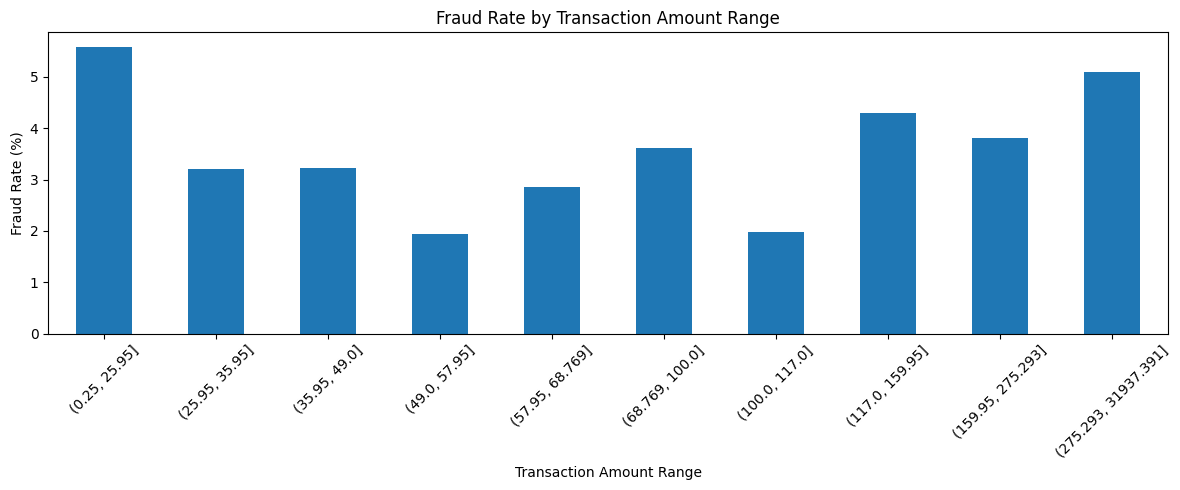

In [17]:
train["Amount_Bin"] = pd.qcut(
    train["TransactionAmt"],
    q=10,
    duplicates="drop"
)

fraud_rate_by_amount = (
    train.groupby("Amount_Bin", observed=True)["isFraud"]
    .mean() * 100
)

plt.figure(figsize=(12, 5))

fraud_rate_by_amount.plot(
    kind="bar",
    rot=45
)

plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

Analyze Product Category

In [18]:
pd.crosstab(
    train["ProductCD"],
    train["isFraud"],
    normalize="index"
) * 100

isFraud,0,1
ProductCD,,
C,88.312731,11.687269
H,95.233769,4.766231
R,96.217406,3.782594
S,94.100447,5.899553
W,97.960061,2.039939


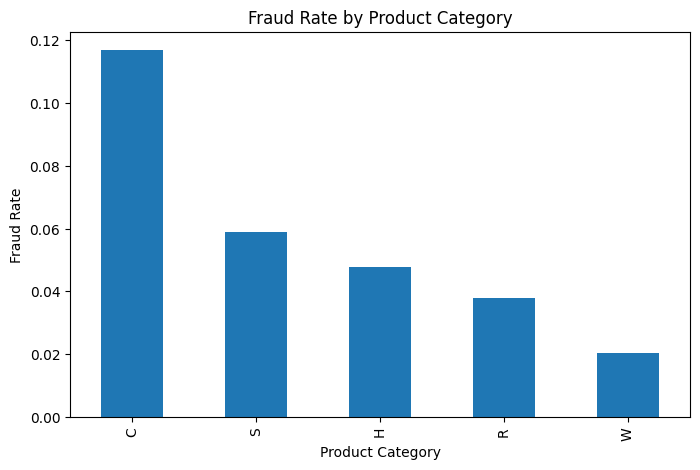

In [19]:
fraud_by_product = (
    train.groupby("ProductCD")["isFraud"]
    .mean()
    .sort_values(ascending=False)
)

fraud_by_product.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Rate")

plt.show()

Analyze transaction time

In [20]:
train["TransactionHour"] = (
    (train["TransactionDT"] // 3600) % 24
)

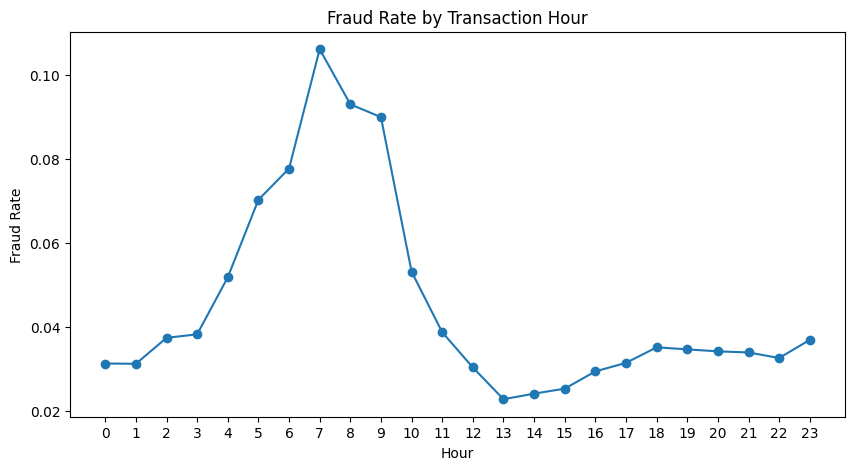

In [21]:
fraud_by_hour = (
    train.groupby("TransactionHour")["isFraud"]
    .mean()
)

fraud_by_hour.plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Hour")
plt.ylabel("Fraud Rate")
plt.xticks(range(24))

plt.show()

Analyze device information

In [22]:
device_fraud = (
    train.groupby("DeviceType")["isFraud"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "fraud_rate"})
    .sort_values("fraud_rate", ascending=False)
)


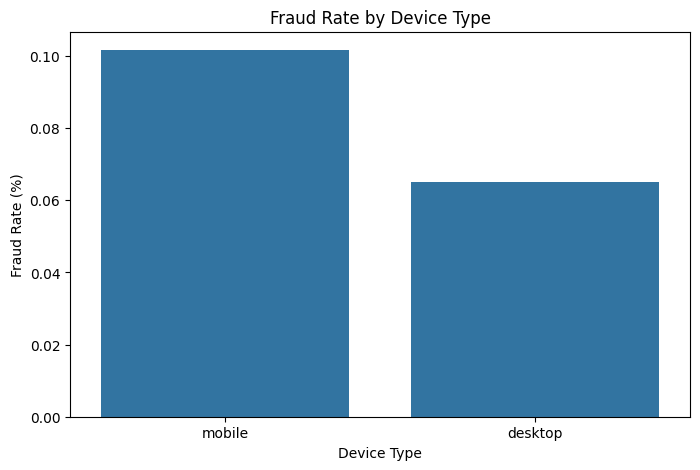

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_fraud.reset_index(),
    x="DeviceType",
    y="fraud_rate"
)

plt.title("Fraud Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

Analyze email domains

In [24]:
email_fraud = (
    train.groupby("P_emaildomain")["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
    .sort_values(
        "transaction_count",
        ascending=False
    )
    .head(20)
)

email_fraud["fraud_percentage"] = (
    email_fraud["fraud_rate"] * 100
).round(2)

email_fraud

,transaction_count,fraud_rate,fraud_percentage
P_emaildomain,,,
gmail.com,228355,0.043542,4.35
yahoo.com,100934,0.022757,2.28
hotmail.com,45250,0.052950,5.30
anonymous.com,36998,0.023217,2.32
aol.com,28289,0.021811,2.18
comcast.net,7888,0.031187,3.12
icloud.com,6267,0.031434,3.14
outlook.com,5096,0.094584,9.46
msn.com,4092,0.021994,2.20


Analyze card-related features

In [25]:
card4_fraud = (
    train.groupby("card4")["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
    .sort_values("fraud_rate", ascending=False)
)

card4_fraud["fraud_percentage"] = (
    card4_fraud["fraud_rate"] * 100
).round(2)

card4_fraud

,transaction_count,fraud_rate,fraud_percentage
card4,,,
discover,6651,0.077282,7.73
visa,384767,0.034756,3.48
mastercard,189217,0.034331,3.43
american express,8328,0.028698,2.87


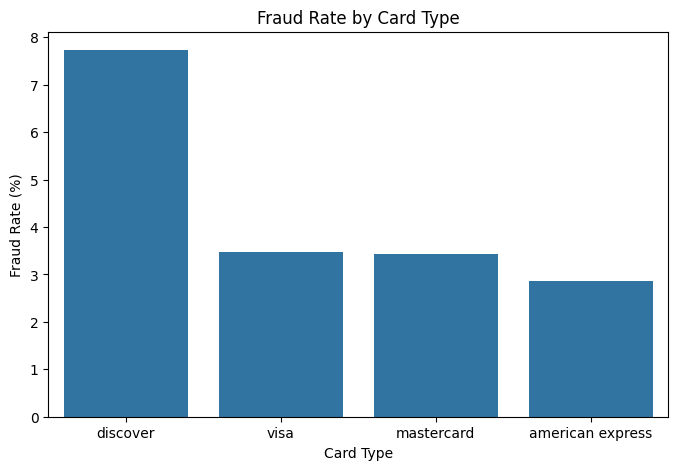

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=card4_fraud.reset_index(),
    x="card4",
    y="fraud_percentage"
)

plt.title("Fraud Rate by Card Type")
plt.xlabel("Card Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

In [27]:
card6_fraud = (
    train.groupby("card6")["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
    .sort_values("fraud_rate", ascending=False)
)

card6_fraud["fraud_percentage"] = (
    card6_fraud["fraud_rate"] * 100
).round(2)

card6_fraud

,transaction_count,fraud_rate,fraud_percentage
card6,,,
credit,148986,0.066785,6.68
debit,439938,0.024263,2.43
charge card,15,0.000000,0.00
debit or credit,30,0.000000,0.00


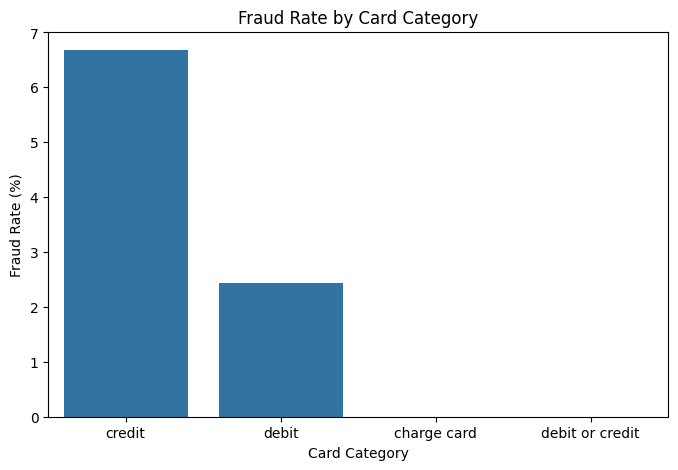

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=card6_fraud.reset_index(),
    x="card6",
    y="fraud_percentage"
)

plt.title("Fraud Rate by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Fraud Rate (%)")

plt.show()

Analyze the M features

In [29]:
m_cols = [f"M{i}" for i in range(1, 10)]

m_summary = []

for col in m_cols:
    fraud_rate = train.groupby(col)["isFraud"].mean() * 100
    
    for category, rate in fraud_rate.items():
        m_summary.append({
            "Feature": col,
            "Category": category,
            "Fraud_Rate": round(rate, 2)
        })

m_summary = pd.DataFrame(m_summary)

m_summary.head(20)

,Feature,Category,Fraud_Rate
0,M1,F,0.00
1,M1,T,1.99
2,M2,F,3.49
3,M2,T,1.81
4,M3,F,3.03
5,M3,T,1.71
6,M4,M0,3.66
7,M4,M1,2.71
8,M4,M2,11.37
9,M5,F,2.65


Check whether missing values themselves relate to fraud

In [30]:
train["DeviceInfo_Missing"] = train["DeviceInfo"].isna()

device_missing_fraud = (
    train.groupby("DeviceInfo_Missing")["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
)

device_missing_fraud["fraud_percentage"] = (
    device_missing_fraud["fraud_rate"] * 100
).round(2)

device_missing_fraud

,transaction_count,fraud_rate,fraud_percentage
DeviceInfo_Missing,,,
False,118666,0.072531,7.25
True,471874,0.025549,2.55


In [31]:
train["P_emaildomain_Missing"] = train["P_emaildomain"].isna()

email_missing_fraud = (
    train.groupby("P_emaildomain_Missing")["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
)

email_missing_fraud["fraud_percentage"] = (
    email_missing_fraud["fraud_rate"] * 100
).round(2)

email_missing_fraud

,transaction_count,fraud_rate,fraud_percentage
P_emaildomain_Missing,,,
False,496084,0.036028,3.60
True,94456,0.029538,2.95


Analyze numerical features

In [32]:
numeric_cols = train.select_dtypes(include=np.number).columns

fraud_corr = (
    train[numeric_cols]
    .corr()["isFraud"]
    .drop("isFraud")
    .abs()
    .sort_values(ascending=False)
)

fraud_corr.head(20)

V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
V200    0.318783
V189    0.308219
V188    0.303582
V258    0.297151
V45     0.281832
V158    0.278066
V156    0.275952
V149    0.273282
V228    0.268861
V44     0.260376
V86     0.251828
V87     0.251737
V170    0.249794
V147    0.242894
V52     0.239469
Name: isFraud, dtype: float64

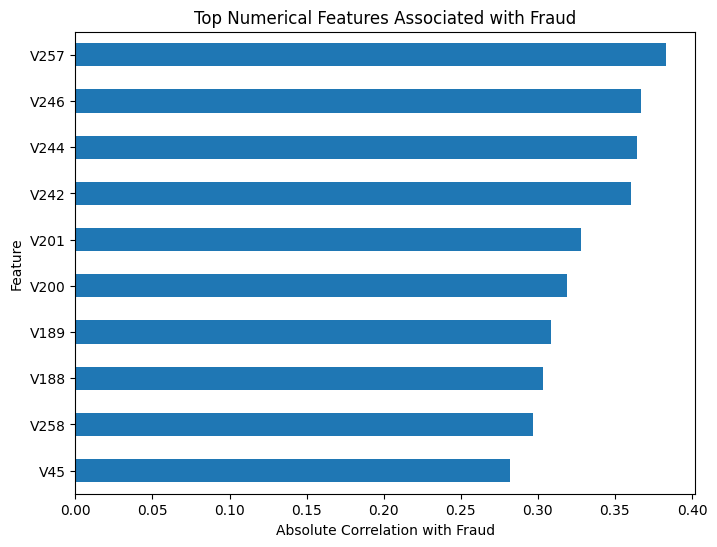

In [33]:
top_corr = fraud_corr.head(10).sort_values()

plt.figure(figsize=(8, 6))

top_corr.plot(kind="barh")

plt.title("Top Numerical Features Associated with Fraud")
plt.xlabel("Absolute Correlation with Fraud")
plt.ylabel("Feature")

plt.show()

Check cardinality of categorical features

In [34]:
categorical_cols = train.select_dtypes(include="object").columns

categorical_summary = pd.DataFrame({
    "Unique_Values": train[categorical_cols].nunique(),
    "Missing_Percentage": train[categorical_cols].isnull().mean() * 100
}).sort_values(
    "Unique_Values",
    ascending=False
)

categorical_summary.head(30)

,Unique_Values,Missing_Percentage
DeviceInfo,1786,79.905510
id_33,260,87.589494
id_31,130,76.245132
id_30,75,86.865411
R_emaildomain,60,76.751617
P_emaildomain,59,15.994852
ProductCD,5,0.000000
card6,4,0.266028
card4,4,0.267044
id_34,4,86.824771


In [35]:
train["Amount_Range"] = pd.qcut(
    train["TransactionAmt"],
    q=10,
    duplicates="drop"
)

amount_fraud = (
    train.groupby("Amount_Range", observed=True)["isFraud"]
    .agg(
        transaction_count="count",
        fraud_rate="mean"
    )
)

amount_fraud["fraud_percentage"] = (
    amount_fraud["fraud_rate"] * 100
).round(2)

amount_fraud

,transaction_count,fraud_rate,fraud_percentage
Amount_Range,,,
"(0.25, 25.95]",59511,0.055889,5.59
"(25.95, 35.95]",61650,0.032052,3.21
"(35.95, 49.0]",65116,0.032250,3.23
"(49.0, 57.95]",59647,0.019431,1.94
"(57.95, 68.769]",49346,0.028513,2.85
"(68.769, 100.0]",73349,0.036170,3.62
"(100.0, 117.0]",72079,0.019742,1.97
"(117.0, 159.95]",32399,0.043026,4.30
"(159.95, 275.293]",58390,0.038037,3.80


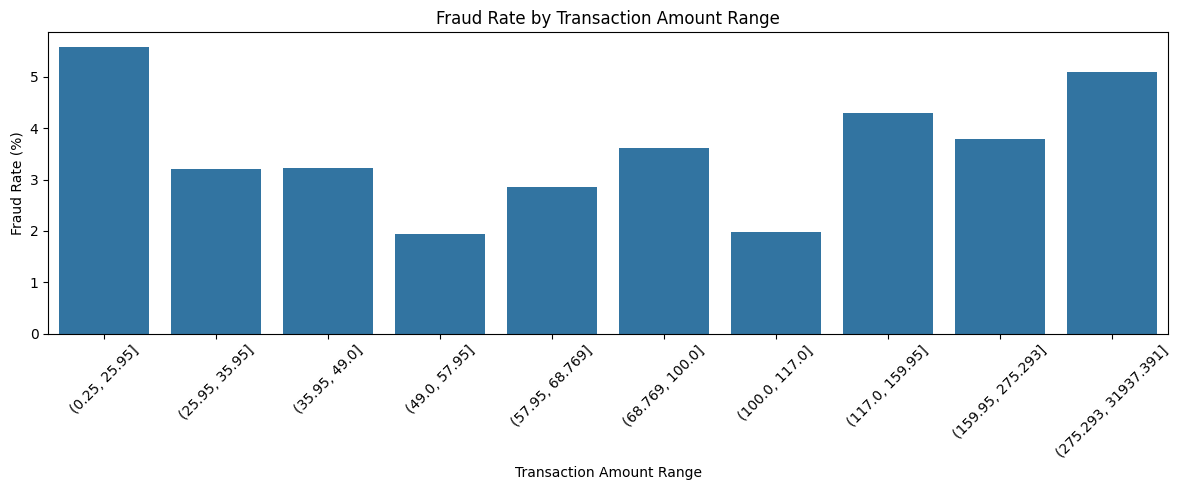

In [36]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=amount_fraud.reset_index(),
    x="Amount_Range",
    y="fraud_percentage"
)

plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Feature Engineering

Create a clean modeling copy

In [36]:
# Create copies for modeling

train_model = train.copy()
test_model = test.copy()

print("Train shape:", train_model.shape)
print("Test shape:", test_model.shape)

Train shape: (590540, 439)
Test shape: (506691, 433)


Transaction time features

In [38]:
# Transaction time features

train_model["TransactionHour"] = (
    (train_model["TransactionDT"] // 3600) % 24
)

test_model["TransactionHour"] = (
    (test_model["TransactionDT"] // 3600) % 24
)

train_model["TransactionDay"] = (
    train_model["TransactionDT"] // (3600 * 24)
)

test_model["TransactionDay"] = (
    test_model["TransactionDT"] // (3600 * 24)
)

Transaction Amount Features

In [39]:
# Log transformation of transaction amount

train_model["TransactionAmt_log"] = np.log1p(
    train_model["TransactionAmt"]
)

test_model["TransactionAmt_log"] = np.log1p(
    test_model["TransactionAmt"]
)

In [40]:
# Transaction amount categories

def amount_category(amount):
    if amount < 50:
        return "Low"
    elif amount < 200:
        return "Medium"
    elif amount < 1000:
        return "High"
    else:
        return "Very_High"


train_model["AmountCategory"] = (
    train_model["TransactionAmt"]
    .apply(amount_category)
)

test_model["AmountCategory"] = (
    test_model["TransactionAmt"]
    .apply(amount_category)
)

Missingness Features

In [41]:
# Identity-related columns that actually exist

identity_cols_train = [
    col for col in train_model.columns
    if col.startswith("id_")
]

identity_cols_test = [
    col for col in test_model.columns
    if col.startswith("id_")
]

print("Identity columns in train:", len(identity_cols_train))
print("Identity columns in test:", len(identity_cols_test))

Identity columns in train: 38
Identity columns in test: 0


In [42]:
# M-feature columns

m_cols = [
    col for col in train_model.columns
    if col.startswith("M")
]

train_model["MMissingCount"] = (
    train_model[m_cols].isna().sum(axis=1)
)

test_model["MMissingCount"] = (
    test_model[m_cols].isna().sum(axis=1)
)

In [43]:
train_model["DeviceInfo_Missing"] = (
    train_model["DeviceInfo"].isna().astype(int)
)

test_model["DeviceInfo_Missing"] = (
    test_model["DeviceInfo"].isna().astype(int)
)

In [44]:
train_model["P_emaildomain_Missing"] = (
    train_model["P_emaildomain"].isna().astype(int)
)

test_model["P_emaildomain_Missing"] = (
    test_model["P_emaildomain"].isna().astype(int)
)

Email Domain Relationship Feature

In [45]:
# Replace missing values temporarily for comparison

train_model["EmailDomainMatch"] = (
    train_model["P_emaildomain"]
    .fillna("Missing")
    ==
    train_model["R_emaildomain"]
    .fillna("Missing")
).astype(int)

test_model["EmailDomainMatch"] = (
    test_model["P_emaildomain"]
    .fillna("Missing")
    ==
    test_model["R_emaildomain"]
    .fillna("Missing")
).astype(int)

Time-Based Train/Validation Split

In [46]:
# Sort transactions chronologically

train_model = train_model.sort_values(
    "TransactionDT"
).reset_index(drop=True)

In [47]:
# Time-based split

split_index = int(len(train_model) * 0.80)

train_part = train_model.iloc[:split_index].copy()
valid_part = train_model.iloc[split_index:].copy()

print("Training data:", train_part.shape)
print("Validation data:", valid_part.shape)

Training data: (472432, 444)
Validation data: (118108, 444)


In [48]:
print("Training TransactionDT:")
print(train_part["TransactionDT"].min())
print(train_part["TransactionDT"].max())

print("\nValidation TransactionDT:")
print(valid_part["TransactionDT"].min())
print(valid_part["TransactionDT"].max())

Training TransactionDT:
86400
12192842

Validation TransactionDT:
12192900
15811131


Frequency Encoding

In [49]:
frequency_columns = [
    "card1",
    "card2",
    "card3",
    "card5",
    "DeviceInfo",
    "P_emaildomain"
]

In [50]:
for col in frequency_columns:

    frequency_map = (
        train_part[col]
        .value_counts()
    )

    train_part[col + "_Freq"] = (
        train_part[col]
        .map(frequency_map)
        .fillna(0)
    )

    valid_part[col + "_Freq"] = (
        valid_part[col]
        .map(frequency_map)
        .fillna(0)
    )

In [51]:
for col in frequency_columns:

    frequency_map = (
        train_part[col]
        .value_counts()
    )

    test_model[col + "_Freq"] = (
        test_model[col]
        .map(frequency_map)
        .fillna(0)
    )

Create the Target Variable

In [52]:
target = "isFraud"

X_train = train_part.drop(
    columns=[target]
)

y_train = train_part[target]

X_valid = valid_part.drop(
    columns=[target]
)

y_valid = valid_part[target]

In [53]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (472432, 449)
y_train: (472432,)
X_valid: (118108, 449)
y_valid: (118108,)


Remove ID Columns

In [54]:
X_train = X_train.drop(
    columns=["TransactionID"],
    errors="ignore"
)

X_valid = X_valid.drop(
    columns=["TransactionID"],
    errors="ignore"
)

test_model = test_model.drop(
    columns=["TransactionID"],
    errors="ignore"
)

Remove the Raw TransactionDT

In [55]:
X_train = X_train.drop(
    columns=["TransactionDT"],
    errors="ignore"
)

X_valid = X_valid.drop(
    columns=["TransactionDT"],
    errors="ignore"
)

test_model = test_model.drop(
    columns=["TransactionDT"],
    errors="ignore"
)

Identify Numerical and Categorical Columns

In [56]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 413
Categorical features: 32


Handle High-Cardinality Categorical Variables

In [57]:
high_cardinality_cols = [
    "card1",
    "card2",
    "card3",
    "card5",
    "DeviceInfo"
]

X_train = X_train.drop(
    columns=high_cardinality_cols,
    errors="ignore"
)

X_valid = X_valid.drop(
    columns=high_cardinality_cols,
    errors="ignore"
)

test_model = test_model.drop(
    columns=high_cardinality_cols,
    errors="ignore"
)

Re-identify Features

In [58]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical:", len(numeric_features))
print("Categorical:", len(categorical_features))

Numerical: 409
Categorical: 31


Build the Preprocessing Pipeline

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [61]:
# Median Imputation

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

In [63]:
# One hot encoding

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [64]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

## Building the ML Models

First Model — Logistic Regression

In [65]:
from sklearn.linear_model import LogisticRegression

In [66]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

In [67]:
logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            logistic_model
        )
    ]
)

In [68]:
logistic_pipeline.fit(
    X_train,
    y_train
)

C:\Users\Hitarth Parikh\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [69]:
y_pred_lr = logistic_pipeline.predict(
    X_valid
)

y_prob_lr = logistic_pipeline.predict_proba(
    X_valid
)[:, 1]

In [70]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [71]:
print(
    classification_report(
        y_valid,
        y_pred_lr
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_valid,
        y_prob_lr
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_valid,
        y_prob_lr
    )
)

              precision    recall  f1-score   support

           0       0.98      0.81      0.89    114044
           1       0.10      0.62      0.18      4064

    accuracy                           0.80    118108
   macro avg       0.54      0.72      0.53    118108
weighted avg       0.95      0.80      0.86    118108

ROC-AUC: 0.7786341836532494
PR-AUC: 0.1225961044578197


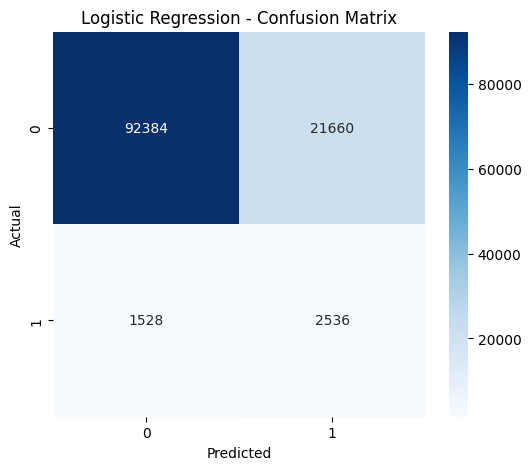

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_valid,
    y_pred_lr
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Random Forest

In [73]:
from sklearn.ensemble import RandomForestClassifier

In [74]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)

In [75]:
rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            rf_model
        )
    ]
)

In [76]:
rf_pipeline.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [77]:
y_pred_rf = rf_pipeline.predict(
    X_valid
)

y_prob_rf = rf_pipeline.predict_proba(
    X_valid
)[:, 1]

In [78]:
print(
    classification_report(
        y_valid,
        y_pred_rf
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_valid,
        y_prob_rf
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_valid,
        y_prob_rf
    )
)

              precision    recall  f1-score   support

           0       0.98      0.94      0.96    114044
           1       0.25      0.58      0.35      4064

    accuracy                           0.93    118108
   macro avg       0.62      0.76      0.66    118108
weighted avg       0.96      0.93      0.94    118108

ROC-AUC: 0.8708582086151581
PR-AUC: 0.4481558317419738


## XGBoost 

In [80]:
from xgboost import XGBClassifier

In [81]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 27.46147358274595


In [82]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

In [83]:
xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            xgb_model
        )
    ]
)

In [84]:
xgb_pipeline.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [85]:
y_pred_xgb = xgb_pipeline.predict(
    X_valid
)

y_prob_xgb = xgb_pipeline.predict_proba(
    X_valid
)[:, 1]

In [86]:
print(
    classification_report(
        y_valid,
        y_pred_xgb
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_valid,
        y_prob_xgb
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_valid,
        y_prob_xgb
    )
)

              precision    recall  f1-score   support

           0       0.99      0.90      0.94    114044
           1       0.21      0.75      0.33      4064

    accuracy                           0.89    118108
   macro avg       0.60      0.82      0.64    118108
weighted avg       0.96      0.89      0.92    118108

ROC-AUC: 0.9097946133064543
PR-AUC: 0.5096782828489616


In [87]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "ROC_AUC": [
        roc_auc_score(y_valid, y_prob_lr),
        roc_auc_score(y_valid, y_prob_rf),
        roc_auc_score(y_valid, y_prob_xgb)
    ],
    "PR_AUC": [
        average_precision_score(y_valid, y_prob_lr),
        average_precision_score(y_valid, y_prob_rf),
        average_precision_score(y_valid, y_prob_xgb)
    ]
})

model_results

,Model,ROC_AUC,PR_AUC
0,Logistic Regression,0.778634,0.122596
1,Random Forest,0.870858,0.448156
2,XGBoost,0.909795,0.509678


In [89]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_valid, y_pred_lr),
        accuracy_score(y_valid, y_pred_rf),
        accuracy_score(y_valid, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_valid, y_pred_lr),
        precision_score(y_valid, y_pred_rf),
        precision_score(y_valid, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_valid, y_pred_lr),
        recall_score(y_valid, y_pred_rf),
        recall_score(y_valid, y_pred_xgb)
    ],

    "F1-Score": [
        f1_score(y_valid, y_pred_lr),
        f1_score(y_valid, y_pred_rf),
        f1_score(y_valid, y_pred_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_valid, y_prob_lr),
        roc_auc_score(y_valid, y_prob_rf),
        roc_auc_score(y_valid, y_prob_xgb)
    ],

    "PR-AUC": [
        average_precision_score(y_valid, y_prob_lr),
        average_precision_score(y_valid, y_prob_rf),
        average_precision_score(y_valid, y_prob_xgb)
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.803671,0.104811,0.624016,0.179476,0.778634,0.122596
1,Random Forest,0.926076,0.251199,0.579724,0.350517,0.870858,0.448156
2,XGBoost,0.894605,0.210217,0.748278,0.328225,0.909795,0.509678
